# Sentinel-1 LULC Semantic Segmentation: Model Training

## Objective

This notebook trains a lightweight U-Net for land use and land cover (LULC) semantic segmentation using Sentinel-1 synthetic aperture radar (SAR) imagery.

The model uses only two Sentinel-1 input channels (VV and VH) and predicts eight LULC classes.

### Experimental Workflow

1. Load the DFC2020 Sentinel-1 images and segmentation labels.
2. Construct a lightweight U-Net.
3. Train the model using cross-entropy loss.
4. Monitor training and validation performance.
5. Save the best-performing model.
6. Visualize learning curves and discuss the results.

### Dataset Protocol

- **Training and validation:** Original DFC2020 test set, divided using a reproducible random split.
- **Final test:** Original DFC2020 validation set, reserved for independent evaluation in Notebook 03.
- **Model input:** Sentinel-1 VV and VH only.
- **Target:** Eight LULC segmentation classes.

The original competition splits are repurposed for this course project. Results are therefore not directly comparable with the official DFC2020 leaderboard.

This notebook supports both small CPU smoke tests and larger GPU training runs.

In [1]:
import os
import sys
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset

from IPython.display import display, Markdown

from sar_lulc_monitor.dataset import create_datasets
from sar_lulc_monitor.model import UNet
from sar_lulc_monitor.training import (
    train_one_epoch,
    validate_one_epoch,
    save_checkpoint,
)
from sar_lulc_monitor.metrics import evaluate_segmentation
from sar_lulc_monitor.preprocessing import (
    CLASS_NAMES,
    NUM_CLASSES,
    IGNORE_INDEX,
)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("OS:", platform.platform())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.12.13
PyTorch: 2.14.1
OS: macOS-27.0.1-arm64-arm-64bit
CUDA available: False


In [3]:
# Choose "smoke" for a local CPU test.
# Choose "full" for the Colab GPU experiment.

RUN_MODE = "smoke"  # "smoke" or "full"

PRESETS = {
    "smoke": {
        "device": "cpu",
        "train_samples": 16,
        "val_samples": 8,
        "epochs": 2,
        "batch_size": 2,
        "base_channels": 16,
        "num_workers": 0,
        "early_stopping_patience": 0,
    },
    "full": {
        "device": "auto",
        "train_samples": None,
        "val_samples": None,
        "epochs": 30,
        "batch_size": 8,
        "base_channels": 32,
        "num_workers": 2,
        "early_stopping_patience": 6,
    },
}

CONFIG = {
    **PRESETS[RUN_MODE],
    "seed": 42,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "val_fraction": 0.2,
    "num_classes": NUM_CLASSES,
    "ignore_index": IGNORE_INDEX,
}

# Override any parameter here, if needed:
# CONFIG["train_samples"] = 64
# CONFIG["val_samples"] = 16
# CONFIG["epochs"] = 3

# PROJECT_ROOT must point to the cloned project directory.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Change this if the dataset is stored elsewhere,
# such as Google Drive or another mounted volume.
DATA_ROOT = PROJECT_ROOT / "data" / "raw"

OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "training"
MODEL_ROOT = PROJECT_ROOT / "models"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
MODEL_ROOT.mkdir(parents=True, exist_ok=True)

if CONFIG["device"] == "auto" and torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif CONFIG["device"] != "auto":
    DEVICE = torch.device(CONFIG["device"])
else:
    DEVICE = torch.device("cpu")

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CONFIG["seed"])

RUN_NAME = f"unet_{RUN_MODE}"
CHECKPOINT_PATH = MODEL_ROOT / f"{RUN_NAME}_best.pth"
HISTORY_PATH = OUTPUT_ROOT / f"{RUN_NAME}_history.csv"

print("Run mode:", RUN_MODE)
print("Device:", DEVICE)
print("Data root:", DATA_ROOT)
print("Checkpoint:", CHECKPOINT_PATH)

display(pd.DataFrame(
    [{"Parameter": k, "Value": v} for k, v in CONFIG.items()]
))

Run mode: smoke
Device: cpu
Data root: /Users/z.yang/playground/sar-lulc-monitor/data/raw
Checkpoint: /Users/z.yang/playground/sar-lulc-monitor/models/unet_smoke_best.pth


,Parameter,Value
0,device,cpu
1,train_samples,16
2,val_samples,8
3,epochs,2
4,batch_size,2
5,base_channels,16
6,num_workers,0
7,early_stopping_patience,0
8,seed,42
9,learning_rate,0.001


In [4]:
train_full, val_full, _ = create_datasets(
    DATA_ROOT,
    val_fraction=CONFIG["val_fraction"],
    seed=CONFIG["seed"],
)


def take_subset(dataset, sample_count, seed):
    """Take a reproducible subset without replacement."""
    if sample_count is None:
        return dataset

    if not 1 <= sample_count <= len(dataset):
        raise ValueError(
            f"sample_count must be between 1 and "
            f"{len(dataset)}, got {sample_count}"
        )

    rng = np.random.default_rng(seed)
    indices = rng.choice(
        len(dataset),
        size=sample_count,
        replace=False,
    )

    return Subset(dataset, indices.tolist())


train_dataset = take_subset(
    train_full,
    CONFIG["train_samples"],
    CONFIG["seed"],
)

val_dataset = take_subset(
    val_full,
    CONFIG["val_samples"],
    CONFIG["seed"] + 1,
)

print("Full training samples:", len(train_full))
print("Full validation samples:", len(val_full))
print("Selected training samples:", len(train_dataset))
print("Selected validation samples:", len(val_dataset))

assert len(train_dataset) > 0
assert len(val_dataset) > 0

Full training samples: 4102
Full validation samples: 1026
Selected training samples: 16
Selected validation samples: 8


In [5]:
loader_generator = torch.Generator()
loader_generator.manual_seed(CONFIG["seed"])

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda"),
    generator=loader_generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda"),
)

batch = next(iter(train_loader))

print("Image batch:", batch["image"].shape)
print("Mask batch:", batch["mask"].shape)

assert batch["image"].shape[1] == 2
assert batch["mask"].ndim == 3
assert batch["image"].shape[0] == batch["mask"].shape[0]
assert torch.isfinite(batch["image"]).all()

print("DataLoader check passed.")

Image batch: torch.Size([2, 2, 256, 256])
Mask batch: torch.Size([2, 256, 256])
DataLoader check passed.


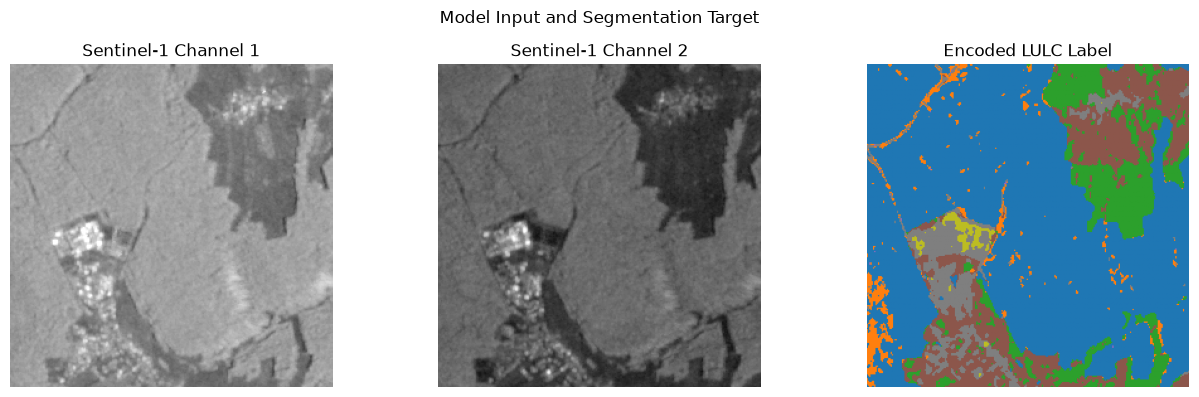

In [6]:
sample = train_dataset[0]

image = sample["image"].numpy()
mask = sample["mask"].numpy()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(image[0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Sentinel-1 Channel 1")

axes[1].imshow(image[1], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Sentinel-1 Channel 2")

axes[2].imshow(mask, cmap="tab10", vmin=0, vmax=7)
axes[2].set_title("Encoded LULC Label")

for ax in axes:
    ax.axis("off")

plt.suptitle("Model Input and Segmentation Target")
plt.tight_layout()
plt.show()

## Model Architecture

A lightweight U-Net is used for pixel-wise LULC segmentation.

The network consists of:

- An encoder with three downsampling stages.
- A bottleneck for learning higher-level spatial features.
- A decoder with three upsampling stages.
- Skip connections that combine encoder and decoder features.
- A final 1×1 convolution producing eight class logits per pixel.

### Design Rationale

U-Net is suitable for this project because it can learn both local spatial patterns and larger contextual features while preserving the spatial resolution required for semantic segmentation.

A relatively small base channel width is selected to reduce computational requirements and make training feasible on a single GPU.

The network is trained from scratch using only the two Sentinel-1 SAR channels. Sentinel-2 imagery is not used as model input.

### Model Architecture
![u-net.svg](../docs/images/u-net.svg)

In [7]:
model = UNet(
    in_channels=2,
    num_classes=CONFIG["num_classes"],
    base_channels=CONFIG["base_channels"],
).to(DEVICE)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# One forward pass to verify the output shape.
model.eval()

with torch.inference_mode():
    dummy = torch.zeros(
        1, 2, 256, 256, device=DEVICE
    )
    output = model(dummy)

print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))

assert output.shape == (
    1, CONFIG["num_classes"], 256, 256
)

del dummy, output

Total parameters: 487,976
Trainable parameters: 487,976
Input shape: (1, 2, 256, 256)
Output shape: (1, 8, 256, 256)


## Training Configuration

The model is trained using the AdamW optimizer and cross-entropy loss.

### Loss Function

Pixel-wise cross-entropy is used for the eight-class segmentation task. The model produces raw logits, which are directly passed to `CrossEntropyLoss`.

The ignore index is set to 255 so that invalid or unsupported reference labels do not contribute to training.

### Model Selection

Validation mean Intersection over Union (mIoU) is used to select the best checkpoint.

The final independent test set is not used during model training or model selection.

### Reproducibility

A fixed random seed is used for model initialization, data splitting, and subset selection.

Small CPU runs are used only for functional verification. The reported experimental results will come from the final GPU training run.

In [9]:
criterion = nn.CrossEntropyLoss(
    ignore_index=CONFIG["ignore_index"]
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"],
)

print("Criterion:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", CONFIG["learning_rate"])
print("Weight decay:", CONFIG["weight_decay"])

Criterion: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001


In [10]:
import time

history = []
best_miou = -float("inf")
best_epoch = None
epochs_without_improvement = 0

start_time = time.perf_counter()

for epoch in range(1, CONFIG["epochs"] + 1):

    epoch_start = time.perf_counter()

    # 1. Training
    train_loss = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=DEVICE,
    )

    # 2. Validation loss
    val_loss = validate_one_epoch(
        model=model,
        loader=val_loader,
        criterion=criterion,
        device=DEVICE,
    )

    # 3. Validation metrics
    val_metrics = evaluate_segmentation(
        model=model,
        loader=val_loader,
        device=DEVICE,
        num_classes=CONFIG["num_classes"],
        ignore_index=CONFIG["ignore_index"],
    )

    val_miou = val_metrics["miou"]
    val_oa = val_metrics["oa"]

    # 4. Save best model
    improved = np.isfinite(val_miou) and (
        val_miou > best_miou
    )

    if improved:
        best_miou = val_miou
        best_epoch = epoch
        epochs_without_improvement = 0

        save_checkpoint(model, CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_seconds = time.perf_counter() - epoch_start

    # 5. Record results
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_miou": val_miou,
        "val_oa": val_oa,
        "epoch_seconds": epoch_seconds,
    })

    # Persist history after each completed epoch.
    pd.DataFrame(history).to_csv(
        HISTORY_PATH, index=False
    )

    print(
        f"Epoch {epoch:03d}/{CONFIG['epochs']:03d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val mIoU: {val_miou:.4f} | "
        f"Val OA: {val_oa:.4f} | "
        f"Time: {epoch_seconds:.1f}s"
        + (" | BEST" if improved else "")
    )

    # 6. Optional early stopping
    patience = CONFIG["early_stopping_patience"]

    if (
        patience > 0
        and epochs_without_improvement >= patience
    ):
        print(
            f"Early stopping after {epoch} epochs."
        )
        break

total_seconds = time.perf_counter() - start_time

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print("Best validation mIoU:", best_miou)
print("Total training time:", round(total_seconds, 1), "s")
print("Checkpoint:", CHECKPOINT_PATH)
print("History:", HISTORY_PATH)

if best_epoch is None:
    raise RuntimeError(
        "No valid checkpoint was saved. "
        "Check validation labels and metrics."
    )

Epoch 001/002 | Train Loss: 2.1051 | Val Loss: 2.0890 | Val mIoU: 0.0077 | Val OA: 0.0618 | Time: 2.7s | BEST
Epoch 002/002 | Train Loss: 1.8869 | Val Loss: 2.0418 | Val mIoU: 0.0243 | Val OA: 0.1350 | Time: 2.3s | BEST

Training finished.
Best epoch: 2
Best validation mIoU: 0.024299536229851922
Total training time: 5.0 s
Checkpoint: /Users/z.yang/playground/sar-lulc-monitor/models/unet_smoke_best.pth
History: /Users/z.yang/playground/sar-lulc-monitor/outputs/training/unet_smoke_history.csv


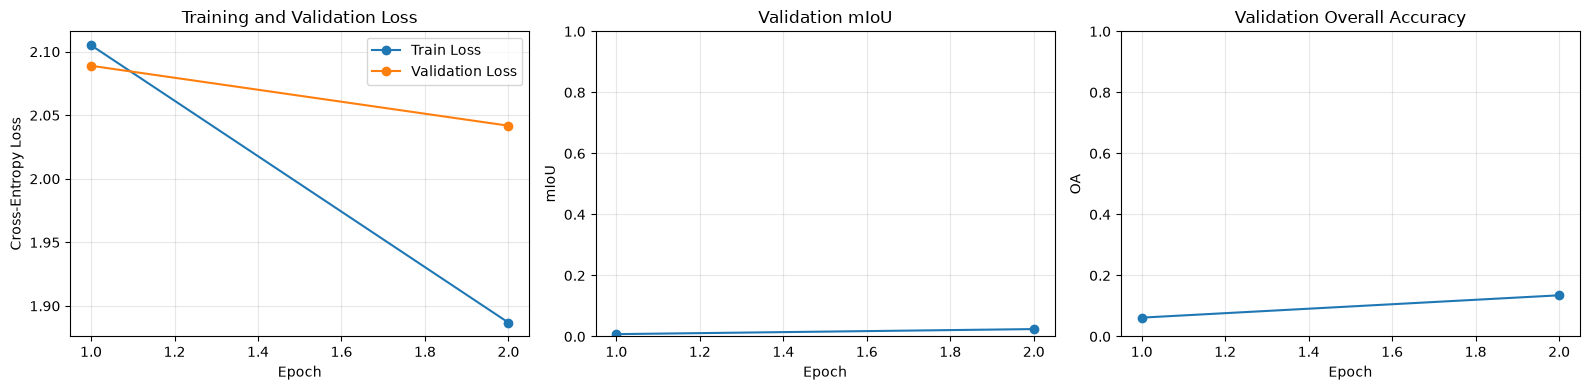

,epoch,train_loss,val_loss,val_miou,val_oa,epoch_seconds
0,1,2.105126,2.088954,0.007727,0.061813,2.699151
1,2,1.886853,2.041777,0.024300,0.134985,2.288798


In [11]:
# Learning curve
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4)
)

# Loss curves
axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss",
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss",
)
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Validation mIoU
axes[1].plot(
    history_df["epoch"],
    history_df["val_miou"],
    marker="o",
)
axes[1].set_title("Validation mIoU")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.3)

# Validation OA
axes[2].plot(
    history_df["epoch"],
    history_df["val_oa"],
    marker="o",
)
axes[2].set_title("Validation Overall Accuracy")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("OA")
axes[2].set_ylim(0, 1)
axes[2].grid(alpha=0.3)

plt.tight_layout()

FIGURE_PATH = OUTPUT_ROOT / f"{RUN_NAME}_curves.png"
plt.savefig(FIGURE_PATH, dpi=150, bbox_inches="tight")
plt.show()

display(history_df)

In [12]:
# Create a fresh model with the same architecture.
best_model = UNet(
    in_channels=2,
    num_classes=CONFIG["num_classes"],
    base_channels=CONFIG["base_channels"],
).to(DEVICE)

state_dict = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True,
)

best_model.load_state_dict(state_dict)
best_model.eval()

print("Best model loaded successfully.")
print("Best epoch:", best_epoch)
print("Best validation mIoU:", round(best_miou, 4))

# Re-evaluate on the validation subset.
best_val_metrics = evaluate_segmentation(
    model=best_model,
    loader=val_loader,
    device=DEVICE,
    num_classes=CONFIG["num_classes"],
    ignore_index=CONFIG["ignore_index"],
)

print("Reloaded model mIoU:", best_val_metrics["miou"])
print("Reloaded model OA:", best_val_metrics["oa"])

assert np.isclose(
    best_val_metrics["miou"],
    best_miou,
    atol=1e-5,
)

Best model loaded successfully.
Best epoch: 2
Best validation mIoU: 0.0243
Reloaded model mIoU: 0.024299536229851922
Reloaded model OA: 0.13498497009277344


In [13]:
# Json store for the model
import json

experiment_info = {
    "run_name": RUN_NAME,
    "model": "UNet",
    "input_channels": 2,
    "num_classes": CONFIG["num_classes"],
    "base_channels": CONFIG["base_channels"],
    "train_samples": len(train_dataset),
    "val_samples": len(val_dataset),
    "epochs_completed": len(history),
    "best_epoch": best_epoch,
    "best_val_miou": float(best_miou),
    "total_training_seconds": total_seconds,
    "configuration": CONFIG,
}

CONFIG_PATH = OUTPUT_ROOT / f"{RUN_NAME}_config.json"

with open(CONFIG_PATH, "w") as f:
    json.dump(experiment_info, f, indent=2)

print("Saved:", CONFIG_PATH)

Saved: /Users/z.yang/playground/sar-lulc-monitor/outputs/training/unet_smoke_config.json


In [15]:
display(Markdown(f"""
## Training Results Summary

| Item | Result |
|---|---|
| Model | Lightweight U-Net |
| Input channels | 2 (Sentinel-1 VV/VH) |
| LULC classes | {CONFIG["num_classes"]} |
| Device | {DEVICE} |
| Training samples | {len(train_dataset)} |
| Validation samples | {len(val_dataset)} |
| Batch size | {CONFIG["batch_size"]} |
| Epochs completed | {len(history)} |
| Best epoch | {best_epoch} |
| Best validation mIoU | {best_miou:.4f} |
| Best validation OA | {best_val_metrics["oa"]:.4f} |
| Training time | {total_seconds:.1f} seconds |

**Model selection:** The best checkpoint was selected
using validation mIoU.

**Independent testing:** The held-out test set has not
been used in this notebook.
"""))


## Training Results Summary

| Item | Result |
|---|---|
| Model | Lightweight U-Net |
| Input channels | 2 (Sentinel-1 VV/VH) |
| LULC classes | 8 |
| Device | cpu |
| Training samples | 16 |
| Validation samples | 8 |
| Batch size | 2 |
| Epochs completed | 2 |
| Best epoch | 2 |
| Best validation mIoU | 0.0243 |
| Best validation OA | 0.1350 |
| Training time | 5.0 seconds |

**Model selection:** The best checkpoint was selected
using validation mIoU.

**Independent testing:** The held-out test set has not
been used in this notebook.
